# $120^\circ$ Néel spin structure

In [7]:
using Random: MersenneTwister

using MX2RKKY

## Plotting routines

In [8]:
using PyPlot; const plt = PyPlot;
plt.pygui(false); plt.svg(true);

function clampΔφ(Δϕ::Float64)
    if Δϕ > π
        return Δϕ - 2π
    elseif Δϕ < -π
        return Δϕ + 2π
    else
        return Δϕ
    end
end

function plot_conf(conf::MX2RKKY.Configuration)
    mpl = plt.matplotlib
    
    i2c = (i1, i2) -> (i1 - 0.5 * i2, √3/2 * i2)
    L1, L2 = size(conf)
    
    # Draw hexagons
    hexagon_verts = []
    hexagon_facecolors = []
    for i1 in 0:(L1-2), i2 in 0:(L2-2)
        tn = MX2RKKY.triangle_nodes((i1, i2), L1, L2)
        ϕ1 = conf.ϕ[tn[1]...]
        ϕ2 = conf.ϕ[tn[2]...]
        ϕ3 = conf.ϕ[tn[3]...]
        χ = Int(round(-(clampΔφ(ϕ2 - ϕ1) + clampΔφ(ϕ3 - ϕ2) + clampΔφ(ϕ1 - ϕ3)) / (2π)))

        hexagon = [i2c(i1, i2),
                   i2c(i1 - 1/3, i2 + 1/3),
                   i2c(i1, i2 + 1),
                   i2c(i1 + 2/3, i2 + 4/3),
                   i2c(i1 + 1, i2 + 1),
                   i2c(i1 + 2/3, i2 + 1/3)]
        push!(hexagon_verts, hexagon)
        push!(hexagon_facecolors, Dict(-1 => "#ffb9b9", 0 => "#ffffff", 1 => "#beecff")[χ])
    end
    hexagon = mpl.collections.PolyCollection(hexagon_verts, edgecolors="black", facecolors=hexagon_facecolors, linewidths=0.5)
    
    xmin, ymax = i2c(0, L2-1)
    xmax, ymin = i2c(L1-1, 0)
    
    fig = plt.figure(figsize=(0.5 * (xmax-xmin), 0.5 * (ymax-ymin)))
    ax = plt.gca()
    ax.add_collection(hexagon)
    
    # Draw spins
    for i in eachindex(conf)
        Sx, Sy = 0.5 * conf.S_vec[1:2, i...] ./ conf.S
        x, y = i2c(i...)
        plt.arrow(x - Sx/2, y - Sy/2, Sx, Sy, color="red", head_width=0.1)
    end

    # Add legend
    plt.legend(handles=[
        mpl.patches.Patch(color="#ffb9b9", label=raw"$\chi=-1$"),
        mpl.patches.Patch(color="#ffffff", label=raw"$\chi=0$"),
        mpl.patches.Patch(color="#beecff", label=raw"$\chi=1$")
    ])

    ax.set_xlim(xmin - 1.0, xmax + 1.0)
    ax.set_ylim(ymin - 1.0, ymax + 1.0)
    plt.show()
    return fig
end

plot_conf (generic function with 1 method)

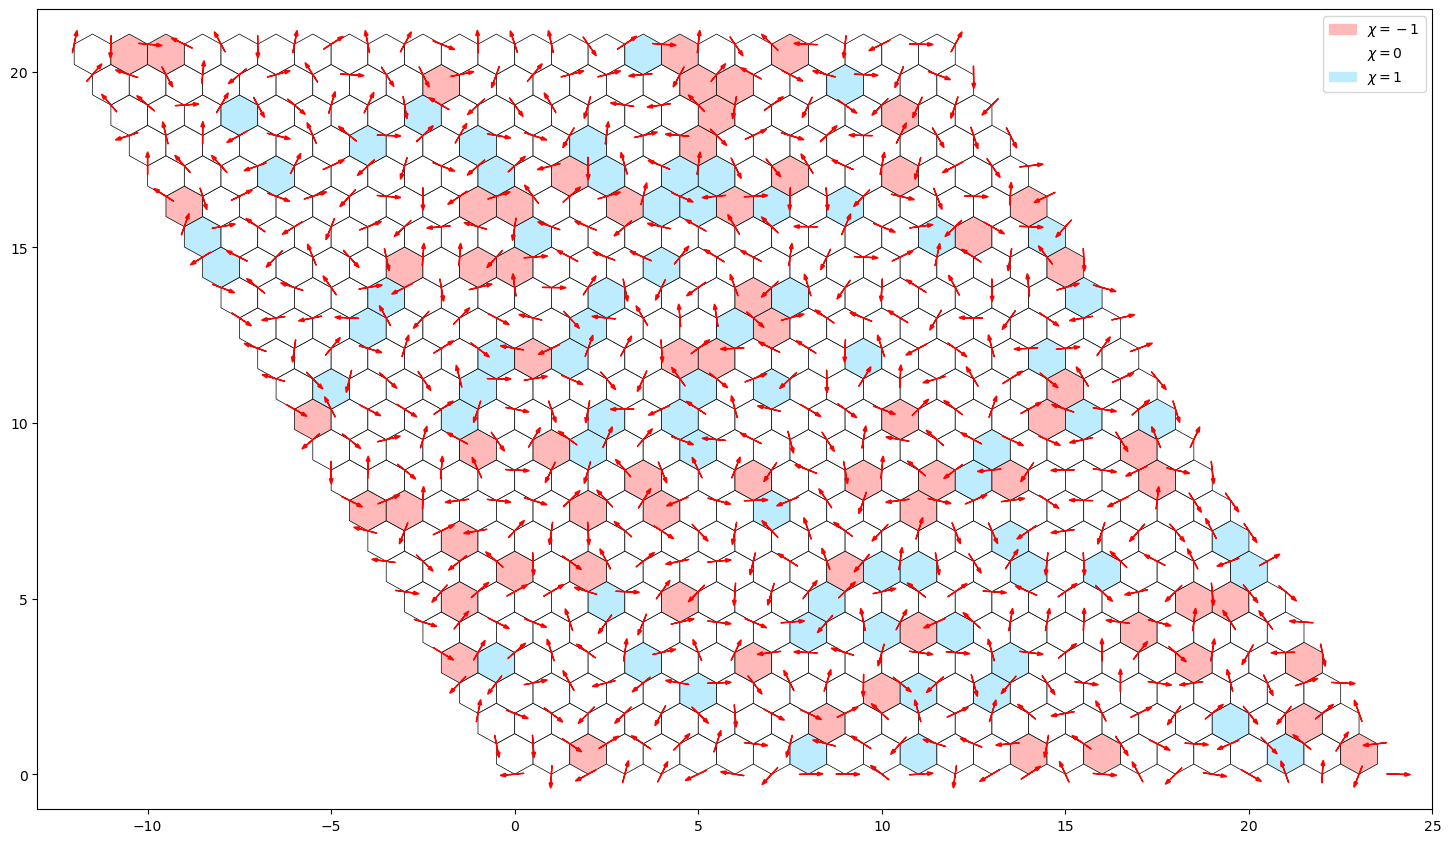

In [9]:
L1, L2 = 25, 25
rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)
plot_conf(conf);

In [155]:
# Cluster size
L1, L2 = 25, 25
N = L1 * L2

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0

# RKKY parameters
Vperp = 0.0
λ = 0.1; # k_F a_0

# $V_\parallel = 0$

In [4]:
Vpar = 0.0

# Temperature scan
T_range = 0.2:0.2:4.0

n_cycles = 2000
n_warmup_cycles = 100
cycle_length = 50

χ_avg = []
χ_var = []

for T in T_range
    rng = MersenneTwister(123456)
    conf = Configuration(L1, L2, rng, inplane=true)
    sim = MCSimulation(conf, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
    run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)

    @show T
    @show acceptance_rates(sim)
    @show avg_chirality(sim)
    @show var_chirality(sim)

    push!(χ_avg, avg_chirality(sim))
    push!(χ_var, var_chirality(sim))
end

LoadError: InterruptException:

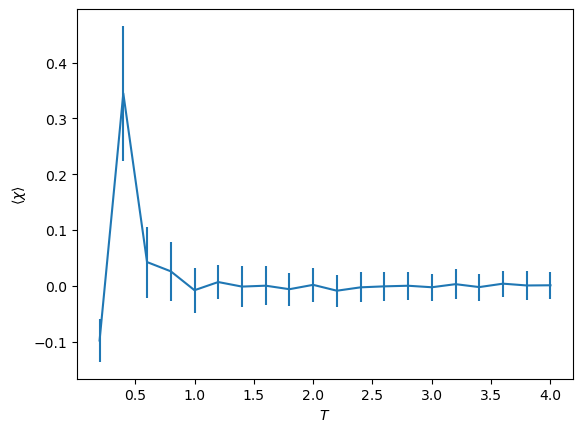

PyObject Text(28.0, 0.5, '$\\langle\\chi\\rangle$')

In [14]:
plt.errorbar(collect(T_range), χ_avg, yerr=χ_var)
plt.xlabel(raw"$T$")
plt.ylabel(raw"$\langle\chi\rangle$")

In [11]:
# Cluster size
L1, L2 = 25, 25

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0
Vpar = 0.0
Vperp = 0.0
λ = 0.1 # k_F a_0
T = 0.01

n_cycles = 1000
n_warmup_cycles = 5000
cycle_length = 50

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)

@show acceptance_rates(sim)
@show avg_chirality(sim)
@show var_chirality(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:15:04


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateSingleSpin{true} => 0.041460217299531185, MX2RKKY.UpdateTriangle => 0.02980839842446091)
avg_chirality(sim) = 0.16653440000000058
var_chirality(sim) = 0.0024059686875196715


0.0024059686875196715

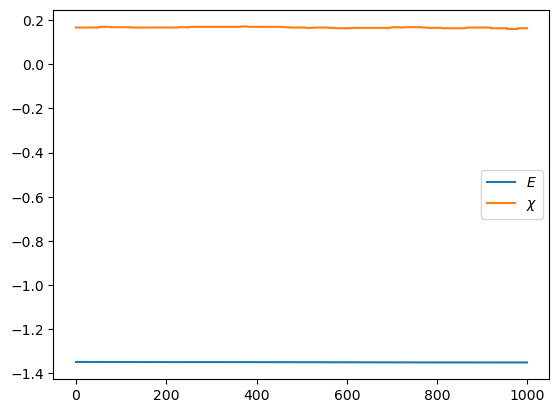

PyObject <matplotlib.legend.Legend object at 0x7f9d61533ef0>

In [12]:
plt.plot(sim.measurements.energy / (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.legend()

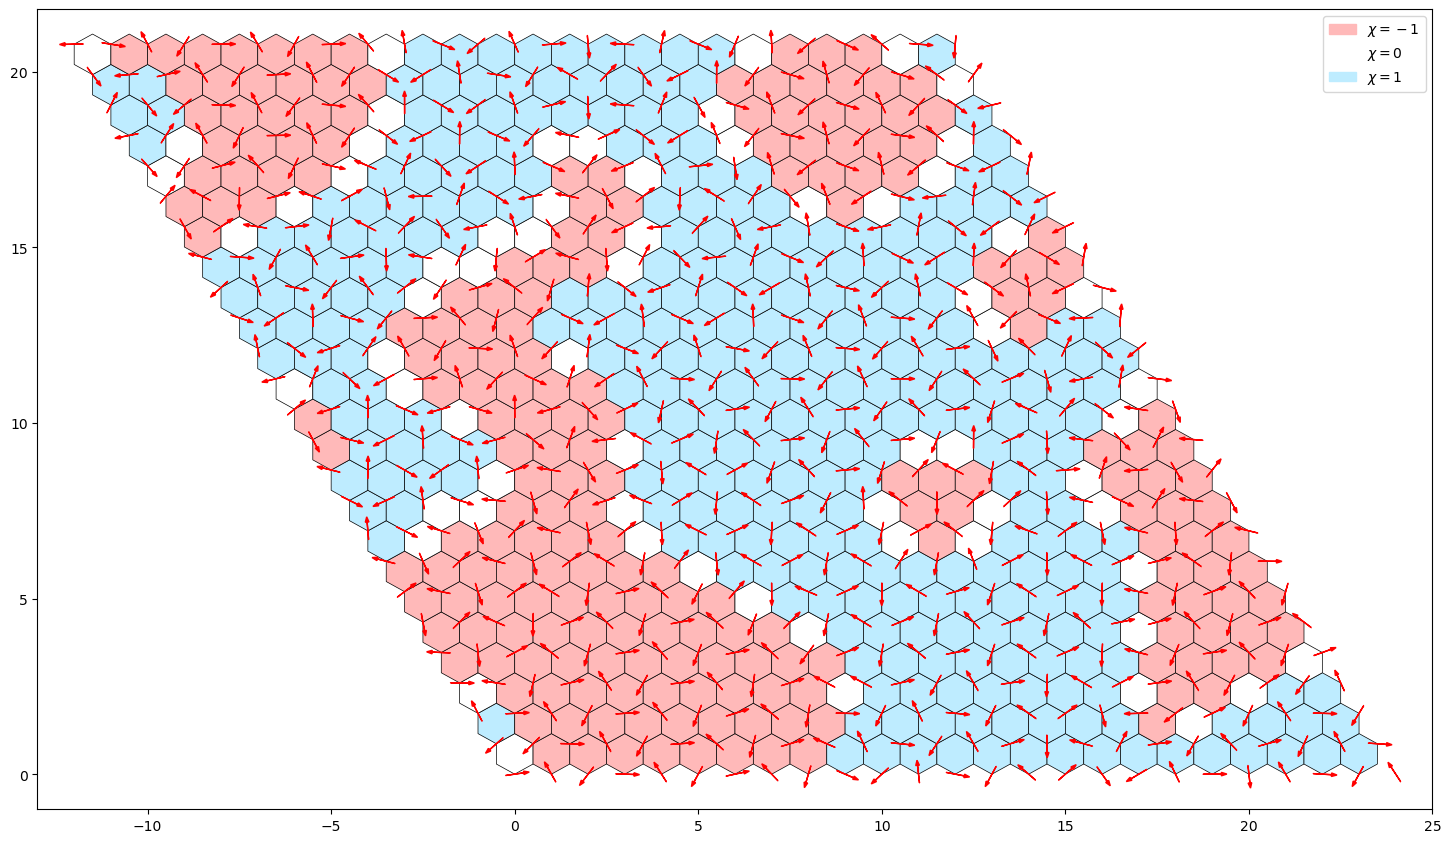

In [13]:
fig = plot_conf(sim.conf);
fig.savefig("conf.pdf")